# Model Reliability and Validation

## Objective

Assess the reliability of the selected repeat-purchase prediction model using existing historical evidence, while distinguishing development results from genuinely independent validation.

## Scope

- Audit the available evaluation populations and chronological boundaries.
- Assess temporal stability and probability calibration.
- Identify limitations in the existing evaluation evidence.
- Establish the additional validation requirements for operational deployment.

## Important Consideration

The original reserved holdout has already been examined during baseline evaluation. Reusing previously examined data must not be presented as a new independent assessment.

This notebook will prioritise transparent model reliability assessment rather than further model optimisation.

In [1]:
# Load existing customer features for the evaluation-data audit

from pathlib import Path
import pandas as pd

project_root = Path.cwd().parent
features_path = project_root / "data" / "processed" / "customer_features.pkl"

customer_features = pd.read_pickle(features_path)

print("Customer features shape:", customer_features.shape)
print("Unique customers:", customer_features["customer_unique_id"].nunique())

print("\nPurchase date range:")
print(customer_features["order_purchase_timestamp"].agg(["min", "max"]))

print("\nAvailable columns:")
print(customer_features.columns.tolist())

Customer features shape: (78100, 29)
Unique customers: 78100

Purchase date range:
min   2016-09-04 21:15:19
max   2018-06-02 23:42:33
Name: order_purchase_timestamp, dtype: datetime64[us]

Available columns:
['customer_unique_id', 'order_id', 'order_purchase_timestamp', 'customer_city', 'customer_state', 'customer_zip_code_prefix', 'repeat_purchase_60d', 'purchase_month', 'purchase_day_of_week', 'purchase_hour', 'first_order_item_count', 'first_order_product_count', 'first_order_seller_count', 'first_order_item_value', 'first_order_freight_value', 'first_order_total_basket_value', 'first_order_total_basket_value_log', 'uses_boleto', 'uses_credit_card', 'uses_debit_card', 'uses_voucher', 'first_order_max_installments', 'first_order_payment_entries', 'payment_method_count', 'first_order_category_count', 'first_order_primary_category', 'primary_category_value', 'first_order_primary_category_share', 'customer_city_state']


In [2]:
# Audit historical model-development and evaluation populations

import numpy as np

purchase_dates = customer_features["order_purchase_timestamp"]

label_observation_end = purchase_dates + pd.Timedelta(days=90)

train_mask = (
    (purchase_dates <= pd.Timestamp("2017-06-30 23:59:59"))
    & (label_observation_end < pd.Timestamp("2017-10-01"))
)

validation_mask = (
    (purchase_dates >= pd.Timestamp("2017-10-01"))
    & (purchase_dates <= pd.Timestamp("2017-12-31 23:59:59"))
    & (label_observation_end < pd.Timestamp("2018-04-01"))
)

test_mask = purchase_dates >= pd.Timestamp("2018-04-01")

population = np.select(
    [train_mask, validation_mask, test_mask],
    ["Training", "Validation", "Previously examined test"],
    default="Outside original splits"
)

audit = customer_features.assign(evaluation_population=population)

population_summary = (
    audit.groupby("evaluation_population")
    .agg(
        customers=("customer_unique_id", "nunique"),
        repeat_purchasers=("repeat_purchase_60d", "sum"),
        first_purchase_min=("order_purchase_timestamp", "min"),
        first_purchase_max=("order_purchase_timestamp", "max")
    )
    .reset_index()
)

population_summary["repeat_rate_pct"] = (
    population_summary["repeat_purchasers"]
    / population_summary["customers"]
    * 100
).round(2)

display(population_summary)

print("\nTotal customers audited:", len(audit))
print("Overlapping assignments:", (
    train_mask.astype(int)
    + validation_mask.astype(int)
    + test_mask.astype(int)
    > 1
).sum())

,evaluation_population,customers,repeat_purchasers,first_purchase_min,first_purchase_max,repeat_rate_pct
0,Outside original splits,32640,738,2017-07-01 00:04:15,2018-03-31 23:54:10,2.26
1,Previously examined test,13649,199,2018-04-01 00:11:32,2018-06-02 23:42:33,1.46
2,Training,14554,321,2016-09-04 21:15:19,2017-06-30 23:20:08,2.21
3,Validation,17257,331,2017-10-01 00:03:33,2017-12-31 23:29:31,1.92



Total customers audited: 78100
Overlapping assignments: 0


In [3]:
# Examine the dates of customers outside the original evaluation splits

outside_splits = audit.loc[
    audit["evaluation_population"] == "Outside original splits"
].copy()

outside_splits["purchase_month"] = (
    outside_splits["order_purchase_timestamp"]
    .dt.to_period("M")
)

monthly_summary = (
    outside_splits.groupby("purchase_month")
    .agg(
        customers=("customer_unique_id", "nunique"),
        repeat_purchasers=("repeat_purchase_60d", "sum")
    )
    .reset_index()
)

monthly_summary["repeat_rate_pct"] = (
    monthly_summary["repeat_purchasers"]
    / monthly_summary["customers"]
    * 100
).round(2)

display(monthly_summary)

print("\nTotal customers outside splits:", len(outside_splits))
print(
    "Earliest first purchase:",
    outside_splits["order_purchase_timestamp"].min()
)
print(
    "Latest first purchase:",
    outside_splits["order_purchase_timestamp"].max()
)

,purchase_month,customers,repeat_purchasers,repeat_rate_pct
0,2017-07,3893,95,2.44
1,2017-08,4184,110,2.63
2,2017-09,4126,99,2.40
3,2018-01,7022,130,1.85
4,2018-02,6450,171,2.65
5,2018-03,6965,133,1.91



Total customers outside splits: 32640
Earliest first purchase: 2017-07-01 00:04:15
Latest first purchase: 2018-03-31 23:54:10


## Evaluation Population Audit: Findings

The historical customer dataset contains 78,100 unique customers with complete observation windows under the established feature-engineering rules.

The reconstructed chronological evaluation populations are:

- Training: 14,554 customers.
- Validation: 17,257 customers.
- Previously examined test: 13,649 customers.
- Outside original splits: 32,640 customers.

The customers outside the original splits belong to July–September 2017 and January–March 2018.

These periods fall between the original modelling and evaluation windows and should not automatically be treated as additional independent validation populations.

The original test population has already been examined during baseline evaluation. The wider historical population has also been used for customer scoring and segmentation.

**Conclusion:** The existing dataset provides useful historical evidence for supplementary reliability assessment, but no genuinely new independent evaluation cohort has been established.

Further model evaluation must distinguish historical diagnostics from independent predictive validation.

In [5]:
# Examine monthly repeat-purchase behaviour across historical customers

monthly_reliability = customer_features.copy()

monthly_reliability["purchase_month"] = (
    monthly_reliability["order_purchase_timestamp"]
    .dt.to_period("M")
)

monthly_repeat_summary = (
    monthly_reliability.groupby("purchase_month")
    .agg(
        customers=("customer_unique_id", "nunique"),
        repeat_purchasers=("repeat_purchase_60d", "sum")
    )
    .reset_index()
)

monthly_repeat_summary["repeat_rate_pct"] = (
    monthly_repeat_summary["repeat_purchasers"]
    / monthly_repeat_summary["customers"]
    * 100
).round(2)

display(monthly_repeat_summary)

print("\nMonths analysed:", len(monthly_repeat_summary))
print("Total customers:", monthly_repeat_summary["customers"].sum())
print("Total repeat purchasers:", monthly_repeat_summary["repeat_purchasers"].sum())

,purchase_month,customers,repeat_purchasers,repeat_rate_pct
0,2016-09,4,0,0.00
1,2016-10,321,3,0.93
2,2016-12,1,1,100.00
3,2017-01,762,27,3.54
4,2017-02,1751,27,1.54
5,2017-03,2635,53,2.01
6,2017-04,2350,42,1.79
7,2017-05,3594,93,2.59
8,2017-06,3136,75,2.39
9,2017-07,3893,95,2.44



Months analysed: 21
Total customers: 78100
Total repeat purchasers: 1589


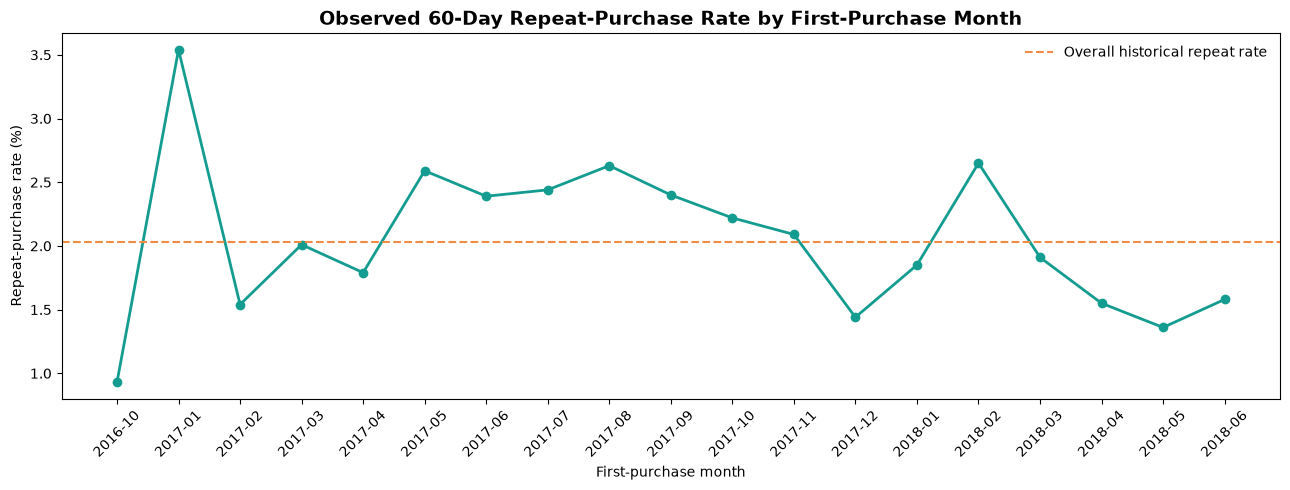

Months included: 19
Customers included: 78095
Customers excluded from chart: 5


In [7]:
# Visualise historical monthly repeat-purchase rates

import matplotlib.pyplot as plt

monthly_plot = monthly_repeat_summary.copy()

# Exclude months with fewer than 100 customers
monthly_plot = monthly_plot.loc[
    monthly_plot["customers"] >= 100
].copy()

monthly_plot["month_label"] = monthly_plot["purchase_month"].astype(str)

fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    monthly_plot["month_label"],
    monthly_plot["repeat_rate_pct"],
    marker="o",
    linewidth=2,
    color="#159C90"
)

ax.axhline(
    y=customer_features["repeat_purchase_60d"].mean() * 100,
    color="#F28C45",
    linestyle="--",
    linewidth=1.5,
    label="Overall historical repeat rate"
)

ax.set_title(
    "Observed 60-Day Repeat-Purchase Rate by First-Purchase Month",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylabel("Repeat-purchase rate (%)")
ax.set_xlabel("First-purchase month")

ax.tick_params(axis="x", rotation=45)
ax.grid(False)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

print("Months included:", len(monthly_plot))
print(
    "Customers included:",
    monthly_plot["customers"].sum()
)
print(
    "Customers excluded from chart:",
    monthly_repeat_summary.loc[
        monthly_repeat_summary["customers"] < 100,
        "customers"
    ].sum()
)

## Temporal Behaviour: Key Findings

Monthly 60-day repeat-purchase rates were examined across the historical customer population.

The visualisation includes 78,095 customers across 19 months. Five customers from months containing fewer than 100 records were excluded from the chart only.

Observed repeat-purchase rates varied across purchasing cohorts, with several later months recording lower rates than earlier periods.

For example:

- August 2017: 2.63%.
- December 2017: 1.44%.
- February 2018: 2.65%.
- May 2018: 1.36%.

These differences indicate temporal variation in customer purchasing behaviour.

However, changes in observed repeat-purchase rates do not independently establish changes in predictive model performance.

Further analysis is required to determine whether the selected model maintains consistent ranking ability and probability reliability across time.

In [8]:
# Load existing historical customer propensity scores

scores_path = (
    project_root
    / "data"
    / "processed"
    / "customer_intelligence_historical.parquet"
)

customer_scores = pd.read_parquet(scores_path)

print("Scored customers:", len(customer_scores))
print("Unique customers:", customer_scores["customer_unique_id"].nunique())

print("\nAvailable columns:")
print(customer_scores.columns.tolist())

print("\nMissing propensity scores:")
print(customer_scores["repeat_purchase_propensity"].isna().sum())

Scored customers: 78100
Unique customers: 78100

Available columns:
['customer_unique_id', 'order_id', 'order_purchase_timestamp', 'first_order_item_value', 'repeat_purchase_propensity', 'propensity_segment', 'initial_value_segment', 'customer_profile', 'repeat_purchase_60d']

Missing propensity scores:
0


In [9]:
# Compare historical predicted and observed repeat-purchase rates by month

monthly_scores = customer_scores.copy()

monthly_scores["purchase_month"] = (
    monthly_scores["order_purchase_timestamp"]
    .dt.to_period("M")
)

monthly_prediction_summary = (
    monthly_scores.groupby("purchase_month")
    .agg(
        customers=("customer_unique_id", "nunique"),
        repeat_purchasers=("repeat_purchase_60d", "sum"),
        mean_predicted_propensity=("repeat_purchase_propensity", "mean")
    )
    .reset_index()
)

monthly_prediction_summary["observed_rate_pct"] = (
    monthly_prediction_summary["repeat_purchasers"]
    / monthly_prediction_summary["customers"]
    * 100
)

monthly_prediction_summary["predicted_rate_pct"] = (
    monthly_prediction_summary["mean_predicted_propensity"] * 100
)

monthly_prediction_summary["prediction_gap_pp"] = (
    monthly_prediction_summary["predicted_rate_pct"]
    - monthly_prediction_summary["observed_rate_pct"]
)

monthly_prediction_summary = monthly_prediction_summary.round(3)

display(monthly_prediction_summary)

print("\nTotal customers:", monthly_prediction_summary["customers"].sum())
print("Months analysed:", len(monthly_prediction_summary))

C:\Users\oades\AppData\Local\Temp\ipykernel_18332\880352052.py:35: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  monthly_prediction_summary = monthly_prediction_summary.round(3)


,purchase_month,customers,repeat_purchasers,mean_predicted_propensity,observed_rate_pct,predicted_rate_pct,prediction_gap_pp
0,2016-09,4,0,0.032,0.000,3.205,3.205
1,2016-10,321,3,0.024,0.935,2.364,1.429
2,2016-12,1,1,0.041,100.000,4.118,-95.882
3,2017-01,762,27,0.022,3.543,2.198,-1.345
4,2017-02,1751,27,0.022,1.542,2.211,0.669
5,2017-03,2635,53,0.022,2.011,2.188,0.177
6,2017-04,2350,42,0.022,1.787,2.188,0.401
7,2017-05,3594,93,0.022,2.588,2.167,-0.421
8,2017-06,3136,75,0.023,2.392,2.257,-0.135
9,2017-07,3893,95,0.024,2.440,2.392,-0.048



Total customers: 78100
Months analysed: 21


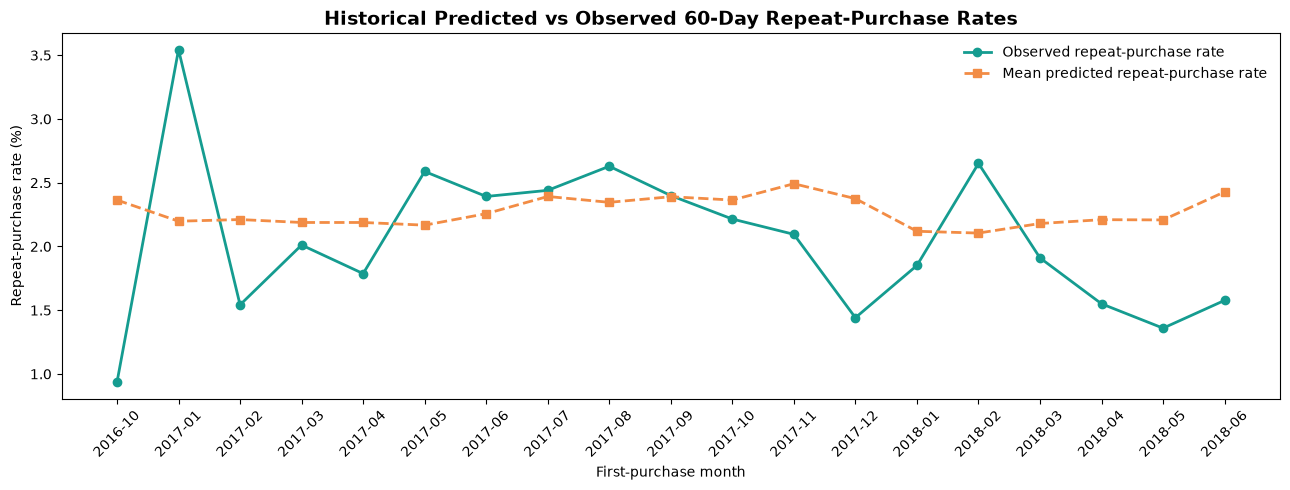

Months included: 19
Customers included: 78095


In [10]:
# Compare observed and predicted repeat-purchase rates across historical months

import matplotlib.pyplot as plt

monthly_comparison = monthly_prediction_summary.loc[
    monthly_prediction_summary["customers"] >= 100
].copy()

monthly_comparison["month_label"] = (
    monthly_comparison["purchase_month"].astype(str)
)

fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    monthly_comparison["month_label"],
    monthly_comparison["observed_rate_pct"],
    marker="o",
    linewidth=2,
    color="#159C90",
    label="Observed repeat-purchase rate"
)

ax.plot(
    monthly_comparison["month_label"],
    monthly_comparison["predicted_rate_pct"],
    marker="s",
    linewidth=2,
    linestyle="--",
    color="#F28C45",
    label="Mean predicted repeat-purchase rate"
)

ax.set_title(
    "Historical Predicted vs Observed 60-Day Repeat-Purchase Rates",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("First-purchase month")
ax.set_ylabel("Repeat-purchase rate (%)")

ax.tick_params(axis="x", rotation=45)
ax.grid(False)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

print("Months included:", len(monthly_comparison))
print("Customers included:", monthly_comparison["customers"].sum())

## Historical Probability Reliability: Findings

The selected model's historical predicted and observed 60-day repeat-purchase rates were compared across first-purchase months.

The visualisation covers 78,095 customers across 19 months. Five customers from very small monthly cohorts were excluded from the chart only.

### Key Observations

- Mean predicted repeat-purchase rates remained relatively stable, generally between 2.1% and 2.5%.
- Observed repeat-purchase rates varied more substantially across customer cohorts.
- The model overpredicted the observed rate in some months and underpredicted it in others.
- In May 2018, the predicted rate was approximately 2.21%, compared with an observed rate of 1.36%.

### Interpretation

The historical results indicate differences between predicted and observed repeat-purchase rates across purchasing periods.

This raises concerns about the reliability of the model's probability estimates and supports the need for further calibration assessment.

However, the analysis includes customers used during model development and therefore does not constitute independent validation.

Monthly average comparisons also do not establish whether the model's customer-ranking performance has changed.

### Business Implication

Predicted probabilities should not yet be treated as sufficiently reliable for automated customer-level marketing decisions.

Independent evaluation and further probability-reliability assessment are required before operational deployment.

In [11]:
# Compare historical probability reliability across evaluation populations

population_scores = customer_scores.merge(
    audit[["customer_unique_id", "evaluation_population"]],
    on="customer_unique_id",
    how="left",
    validate="one_to_one"
)

# Verify that every scored customer has an evaluation assignment
assert len(population_scores) == len(customer_scores)
assert population_scores["evaluation_population"].notna().all()

population_reliability = (
    population_scores.groupby("evaluation_population")
    .agg(
        customers=("customer_unique_id", "nunique"),
        repeat_purchasers=("repeat_purchase_60d", "sum"),
        mean_predicted_propensity=("repeat_purchase_propensity", "mean")
    )
    .reset_index()
)

population_reliability["observed_rate_pct"] = (
    population_reliability["repeat_purchasers"]
    / population_reliability["customers"]
    * 100
)

population_reliability["predicted_rate_pct"] = (
    population_reliability["mean_predicted_propensity"] * 100
)

population_reliability["prediction_gap_pp"] = (
    population_reliability["predicted_rate_pct"]
    - population_reliability["observed_rate_pct"]
)

display(population_reliability.round(3))

print("\nTotal customers:", population_reliability["customers"].sum())
print("Total repeat purchasers:", population_reliability["repeat_purchasers"].sum())

,evaluation_population,customers,repeat_purchasers,mean_predicted_propensity,observed_rate_pct,predicted_rate_pct,prediction_gap_pp
0,Outside original splits,32640,738,0.022,2.261,2.225,-0.036
1,Previously examined test,13649,199,0.022,1.458,2.214,0.756
2,Training,14554,321,0.022,2.206,2.205,-0.000
3,Validation,17257,331,0.024,1.918,2.422,0.504



Total customers: 78100
Total repeat purchasers: 1589


## Probability Reliability by Evaluation Population

The selected model's predicted and observed 60-day repeat-purchase rates were compared across the reconstructed historical evaluation populations.

### Key Findings

- Training: 2.205% predicted versus 2.206% observed.
- Validation: 2.422% predicted versus 1.918% observed.
- Previously examined test: 2.214% predicted versus 1.458% observed.
- Outside original splits: 2.225% predicted versus 2.261% observed.

The validation and previously examined test populations showed average overprediction of approximately 0.50 and 0.76 percentage points respectively.

The near-zero average prediction gap in the training population does not establish reliable individual probability calibration.

### Interpretation

The historical results indicate that probability reliability differs across evaluation populations, with greater average overprediction in the later test period.

However, this analysis does not independently establish changes in customer-ranking performance or demonstrate future predictive reliability.

The previously examined test population is not a fresh holdout, and the scored dataset contains customers used during model development.

### Business Implication

The current model may provide useful historical customer-ranking information, but its probabilities should not yet be relied upon as precise estimates for operational targeting or commercial forecasting.

Further independent validation and appropriate calibration are required before deployment.

In [14]:
# Assess historical probability reliability by propensity segment

segment_order = [
    "Low Propensity",
    "Medium Propensity",
    "High Propensity"
]
segment_reliability = (
    customer_scores.groupby("propensity_segment")
    .agg(
        customers=("customer_unique_id", "nunique"),
        repeat_purchasers=("repeat_purchase_60d", "sum"),
        mean_predicted_propensity=("repeat_purchase_propensity", "mean")
    )
    .reset_index()
)

segment_reliability["observed_rate_pct"] = (
    segment_reliability["repeat_purchasers"]
    / segment_reliability["customers"]
    * 100
)

segment_reliability["predicted_rate_pct"] = (
    segment_reliability["mean_predicted_propensity"] * 100
)

segment_reliability["prediction_gap_pp"] = (
    segment_reliability["predicted_rate_pct"]
    - segment_reliability["observed_rate_pct"]
)

segment_reliability["propensity_segment"] = pd.Categorical(
    segment_reliability["propensity_segment"],
    categories=segment_order,
    ordered=True
)

segment_reliability = (
    segment_reliability
    .sort_values("propensity_segment")
    .reset_index(drop=True)
)

display(segment_reliability.round(3))

print("\nCustomers assessed:", segment_reliability["customers"].sum())
print("Repeat purchasers:", segment_reliability["repeat_purchasers"].sum())
print("Segments assessed:", len(segment_reliability))

,propensity_segment,customers,repeat_purchasers,mean_predicted_propensity,observed_rate_pct,predicted_rate_pct,prediction_gap_pp
0,Low Propensity,39050,536,0.015,1.373,1.531,0.158
1,Medium Propensity,23430,494,0.023,2.108,2.254,0.146
2,High Propensity,15620,559,0.041,3.579,4.106,0.527



Customers assessed: 78100
Repeat purchasers: 1589
Segments assessed: 3


In [13]:
# Inspect the original propensity segment labels

print("Original segment labels:")
print(customer_scores["propensity_segment"].value_counts(dropna=False))

print("\nSegment labels in the reliability table:")
print(segment_reliability["propensity_segment"].value_counts(dropna=False))

Original segment labels:
propensity_segment
Low Propensity       39050
Medium Propensity    23430
High Propensity      15620
Name: count, dtype: int64[pyarrow]

Segment labels in the reliability table:
propensity_segment
NaN       3
Low       0
Medium    0
High      0
Name: count, dtype: int64


## Probability Reliability by Propensity Segment

### Key Findings

Historical predicted and observed 60-day repeat-purchase rates were compared across the three propensity segments.

| Segment | Customers | Observed Rate | Predicted Rate | Prediction Gap |
|---|---:|---:|---:|---:|
| Low Propensity | 39,050 | 1.373% | 1.531% | +0.158 pp |
| Medium Propensity | 23,430 | 2.108% | 2.254% | +0.146 pp |
| High Propensity | 15,620 | 3.579% | 4.106% | +0.527 pp |

### Interpretation

The model overpredicted repeat-purchase rates across all three historical propensity segments.

The largest absolute prediction gap occurred in the High Propensity segment, where the model predicted 4.106% compared with an observed rate of 3.579%.

Although the segments demonstrate increasing observed repeat-purchase rates from Low to High Propensity, this does not establish that the predicted probabilities are accurately calibrated.

The analysis also includes customers used during model development and therefore does not constitute independent validation.

### Business Implications

The current segmentation provides a useful foundation for investigating differences in historical customer behaviour.

However, predicted probabilities should not be treated as precise estimates of future purchasing behaviour or used directly for automated marketing decisions without further validation.

### Conclusion

The results reinforce the need for independent model validation and probability calibration before operational deployment.

## Model Reliability and Deployment Readiness

### Evidence Established

- Historical customer scoring covers 78,100 unique customers.
- Repeat-purchase behaviour varies across historical purchasing periods.
- The model overpredicts average repeat-purchase rates in the validation and previously examined test populations.
- All three propensity segments show positive prediction gaps.
- The historical segments demonstrate different observed repeat-purchase rates, but this does not establish independent predictive performance.

### Current Limitations

- The existing historical data has been used extensively during model development and analysis.
- The original reserved test population has already been examined.
- No genuinely untouched evaluation cohort has been established.
- Post-hoc probability calibration was deferred because the available chronological splits were unsuitable.
- The model has not demonstrated that its predictions can generate incremental commercial value.

### Deployment Assessment

**Current status: Historical analytical prototype, not production-ready.**

The existing model can support exploratory analysis of customer purchasing patterns and historical segmentation.

It should not yet be used for automated customer targeting, precise probability-based forecasting or decisions involving significant marketing expenditure.

### Requirements Before Operational Deployment

1. Obtain new, independently held-out customer data for prospective or out-of-time validation.
2. Establish acceptable predictive discrimination and probability calibration.
3. Evaluate model performance and reliability across customer cohorts.
4. Introduce automated data quality checks and model monitoring.
5. Define a specific business intervention and evaluate its incremental commercial impact through controlled experimentation.

# Conclusion and Business Insights

## Objective

Assess the reliability of the selected repeat-purchase prediction model using historical customer data, while distinguishing exploratory findings from independent predictive validation.

## Key Outcomes

- Audited the chronological evaluation populations covering 78,100 historical customers.
- Identified 32,640 customers outside the original modelling splits and confirmed their purchasing periods.
- Examined monthly repeat-purchase behaviour across historical customer cohorts.
- Compared predicted and observed repeat-purchase rates across purchasing months and evaluation populations.
- Assessed probability reliability across Low, Medium and High Propensity segments.
- Documented the limitations affecting model reliability and deployment readiness.

## Key Findings

### Customer Behaviour Changes Across Time

Observed 60-day repeat-purchase rates varied across historical customer cohorts.

This demonstrates the importance of considering temporal variation when evaluating customer prediction models.

### The Model's Probability Estimates Require Improvement

The model overpredicted repeat purchasing in the validation population by approximately 0.50 percentage points and in the previously examined test population by approximately 0.76 percentage points.

Overprediction was also observed across all three propensity segments.

### Historical Ranking Does Not Establish Future Reliability

The High Propensity segment demonstrated a higher observed repeat-purchase rate than the Low Propensity segment.

However, these historical differences do not constitute independent evidence of predictive performance on future customers.

## Business Implications

The Customer Intelligence Platform provides a foundation for understanding customer purchasing behaviour and investigating potential retention opportunities.

However, the current probability estimates are not sufficiently validated for automated customer-level marketing decisions.

Businesses should not assume that higher predicted repeat-purchase propensity automatically translates into greater commercial value or responsiveness to marketing interventions.

## Limitations

- Historical scoring includes customers used during model development.
- The reserved test population has previously been examined.
- No genuinely untouched independent evaluation cohort was established.
- Post-hoc probability calibration remains deferred.
- No controlled experiment has demonstrated incremental commercial impact.

## Final Assessment

**Model status: Suitable for historical exploration and customer segmentation, but not ready for production deployment.**

The next development stage should prioritise independent validation using new customer cohorts, improved probability calibration and the evaluation of commercially meaningful customer retention strategies.

The objective is to strengthen the Customer Intelligence Platform's reliability before progressing towards operational decision-making.